# Лабораторна робота № 9
## Рекомендаційні системи: SVD, KNNBasic і власний алгоритм

**Мета:** оцінити два методи рекомендацій на MovieLens 100K, виконати GridSearchCV, порівняти RMSE/MAE, підготувати топ-10 та реалізувати незалежний рекомендаційний алгоритм без готового методу Surprise.

## 1. Підготовка середовища
У Google Colab встановлення `scikit-surprise` може вимагати перезапуску середовища після зміни NumPy. Комірки виконуються послідовно; набір MovieLens 100K завантажується з інтернету автоматично.

In [1]:
%pip install -q numpy==2.2.6 scipy==1.15.3 scikit-learn==1.6.1 pandas==2.2.3 scikit-surprise==1.1.5

In [2]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import surprise
from surprise import Dataset, Reader, SVD, KNNBasic, accuracy
from surprise.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split

SEED = 42
print('Python:', sys.version.split()[0], '| Surprise:', surprise.__version__)
print('NumPy:', np.__version__, '| pandas:', pd.__version__)


Python: 3.13.18 | Surprise: 1.1.5
NumPy: 2.4.6 | pandas: 2.2.3


## 2. Первинний аналіз MovieLens 100K
Перевіряємо розмір, кількість користувачів, фільмів, оцінки та пропуски. ID повинні залишатися **рядками** (raw ID для Surprise).

In [3]:
dataset = Dataset.load_builtin('ml-100k', prompt=False)
ratings_df = pd.DataFrame(
    dataset.raw_ratings,
    columns=['user_id', 'item_id', 'rating', 'timestamp'],
)
ratings_df['rating'] = ratings_df['rating'].astype(float)
display(ratings_df.head())
print('Оцінок:', len(ratings_df))
print('Користувачів:', ratings_df.user_id.nunique())
print('Фільмів:', ratings_df.item_id.nunique())
print('Діапазон/середнє:', ratings_df.rating.min(), ratings_df.rating.max(), round(
    ratings_df.rating.mean(), 3))
print('Пропуски:', ratings_df.isna().sum().to_dict())
print('Розподіл:', ratings_df.rating.value_counts().sort_index().to_dict())
assert ratings_df[['user_id', 'item_id', 'rating']].isna().sum().sum() == 0


Trying to download dataset from https://files.grouplens.org/datasets/movielens/ml-100k.zip...
Done! Dataset ml-100k has been saved to /root/.surprise_data/ml-100k


,user_id,item_id,rating,timestamp
0,196,242,3.0,881250949
1,186,302,3.0,891717742
2,22,377,1.0,878887116
3,244,51,2.0,880606923
4,166,346,1.0,886397596


Оцінок: 100000
Користувачів: 943
Фільмів: 1682
Діапазон/середнє: 1.0 5.0 3.53
Пропуски: {'user_id': 0, 'item_id': 0, 'rating': 0, 'timestamp': 0}
Розподіл: {1.0: 6110, 2.0: 11370, 3.0: 27145, 4.0: 34174, 5.0: 21201}


**Спостереження.** Дані містять явні рейтинги в межах 1–5. Матриця користувач–фільм є розрідженою: більшість пар не мають оцінки, тому задача рекомендацій відрізняється від звичайної регресії.

## 3. Розбиття 80/20
Як вимагає шаблон: `random_state=42`. Усе налаштування параметрів проводиться тільки на **80% навчальних рейтингів**.

In [4]:
train_df, test_df = train_test_split(ratings_df, test_size=0.2, random_state=SEED)
reader = Reader(rating_scale=dataset.reader.rating_scale)
train_data = Dataset.load_from_df(train_df[['user_id', 'item_id', 'rating']], reader)
testset = (
    list(test_df[['user_id', 'item_id', 'rating']].itertuples(index=False, name=None))
)
print('Train:', len(train_df), 'Test:', len(testset))
assert len(train_df) + len(testset) == len(ratings_df)
assert len(testset) == len(test_df)


Train: 80000 Test: 20000


## 4. Гіперпараметри
Для SVD зміщено акцент на сильнішу регуляризацію; KNN порівнює item-based косинусну схожість та MSD. В усіх варіантах підбираються SVD фактори, швидкість і регуляризація; для KNN — число сусідів, мінімум сусідів і міра схожості.

In [5]:
param_grid_svd = {
    'n_factors': [30, 70],
    'lr_all': [0.003, 0.007],
    'reg_all': [0.04, 0.08],
}

param_grid_knn = {
    'k': [20, 50],
    'min_k': [2, 5],
    'sim_options': {
        'name': ['cosine', 'msd'],
        'user_based': [False],
    },
}

print(
    'Варіантів SVD:',
    len(param_grid_svd['n_factors'])
    * len(param_grid_svd['lr_all'])
    * len(param_grid_svd['reg_all']),
)
print(
    'Варіантів KNN:',
    len(param_grid_knn['k'])
    * len(param_grid_knn['min_k'])
    * len(param_grid_knn['sim_options']['name'])
    * len(param_grid_knn['sim_options']['user_based']),
)


Варіантів SVD: 8
Варіантів KNN: 8


## 5. Перехресна перевірка, GridSearchCV (CV=3)
RMSE і MAE — дві різні метрики: модель для топ-10 вибираємо за **найкращим CV RMSE**. Навчання GridSearchCV не використовує тестові рейтинги.

In [6]:
grid_search_svd, grid_search_knn = (GridSearchCV(algorithm, grid, measures=['rmse',
    'mae'], cv=3, n_jobs=-1) for algorithm, grid in [(SVD, param_grid_svd), (KNNBasic,
    param_grid_knn)])
for search_model in (grid_search_svd, grid_search_knn):
    search_model.fit(train_data)

print('Параметри обох алгоритмів перевірені на трьох згортках')


Параметри обох алгоритмів перевірені на трьох згортках


In [7]:
cv_results = (
    pd.DataFrame([{'Model': 'SVD', 'CV RMSE': grid_search_svd.best_score['rmse'],
        'CV MAE (мінімум)': grid_search_svd.best_score['mae']}, {'Model': 'KNNBasic',
        'CV RMSE': grid_search_knn.best_score['rmse'],
        'CV MAE (мінімум)': grid_search_knn.best_score['mae']}]).sort_values('CV RMSE')
)
display(cv_results.round(4))
print('SVD — найкращі параметри за RMSE:', grid_search_svd.best_params['rmse'])
print('KNN — найкращі параметри за RMSE:', grid_search_knn.best_params['rmse'])
print('Примітка: мінімальні RMSE і MAE у пошуку можуть відповідати різним конфігураціям.')


,Model,CV RMSE,CV MAE (мінімум)
0,SVD,0.9429,0.7459
1,KNNBasic,1.0018,0.7951


SVD — найкращі параметри за RMSE: {'n_factors': 70, 'lr_all': 0.007, 'reg_all': 0.08}
KNN — найкращі параметри за RMSE: {'k': 50, 'min_k': 2, 'sim_options': {'name': 'msd', 'user_based': False}}
Примітка: мінімальні RMSE і MAE у пошуку можуть відповідати різним конфігураціям.


## 6. Остаточні моделі
Перестворюємо обидва алгоритми з параметрами, підібраними **за CV RMSE**, і навчаємо на всій тренувальній частині.

In [8]:
trainset = train_data.build_full_trainset()
best_svd_params = grid_search_svd.best_params['rmse']
best_knn_params = grid_search_knn.best_params['rmse']
best_svd = SVD(**best_svd_params, random_state=SEED)
best_knn = KNNBasic(**best_knn_params, verbose=False)
best_svd.fit(trainset)
best_knn.fit(trainset)
print('Фінальні моделі готові')


Фінальні моделі готові


## 7. Незалежна перевірка
На тестовій частині один раз визначаємо RMSE та MAE. **Вибір алгоритму для рекомендацій не залежить від тесту.**

In [9]:
svd_predictions = best_svd.test(testset)
knn_predictions = best_knn.test(testset)
svd_rmse = accuracy.rmse(svd_predictions, verbose=False)
svd_mae = accuracy.mae(svd_predictions, verbose=False)
knn_rmse = accuracy.rmse(knn_predictions, verbose=False)
knn_mae = accuracy.mae(knn_predictions, verbose=False)
results = (
    pd.DataFrame({'Model': ['SVD', 'KNNBasic'], 'RMSE': [svd_rmse, knn_rmse], 'MAE': [
        svd_mae, knn_mae]})
)
results = results.sort_values('RMSE')
display(results.round(4))


,Model,RMSE,MAE
0,SVD,0.9254,0.7314
1,KNNBasic,0.9736,0.7693


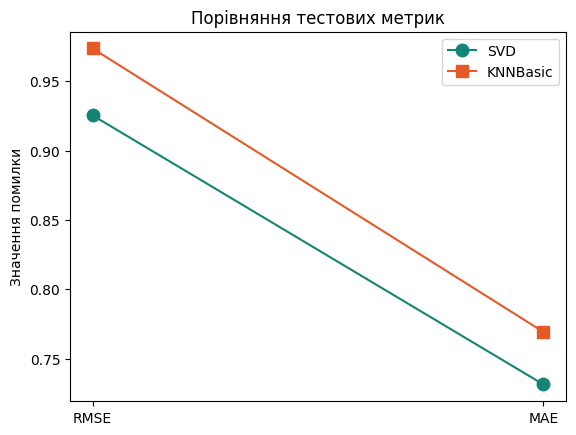

In [10]:
plot_data = (
    results.melt(id_vars='Model', value_vars=['RMSE', 'MAE'], var_name='Критерій',
        value_name='Помилка')
)
for name, marker, color in [('SVD', 'o', '#148575'), ('KNNBasic', 's', '#e65a27')]:
    selected = plot_data.query('Model == @name')
    plt.plot(selected['Критерій'], selected['Помилка'], marker=marker, markersize=9,
        color=color, label=name)

plt.ylabel('Значення помилки')
plt.title('Порівняння тестових метрик')
plt.legend()
plt.show()


## 8. 10 рекомендацій для конкретного користувача
Беремо модель із мінімальним CV RMSE; **відкидаємо всі фільми, уже оцінені користувачем у навчальній вибірці**; рейтинги прогнозуються тільки для решти фільмів. Перевіряємо наявність user ID.

In [11]:
user_id = '305'
all_train_users = {trainset.to_raw_uid(i) for i in trainset.all_users()}
if user_id not in all_train_users:
    print('Користувач не зустрівся у train, використано наявний raw ID.')
    user_id = trainset.to_raw_uid(0)

svd_is_better = grid_search_svd.best_score['rmse'] <= grid_search_knn.best_score['rmse']
best_model = best_svd if svd_is_better else best_knn
chosen_name = 'SVD' if svd_is_better else 'KNNBasic'
inner_uid = trainset.to_inner_uid(user_id)
rated_items = {
    trainset.to_raw_iid(inner_iid)
    for inner_iid, _ in trainset.ur[inner_uid]
}
all_train_items = {trainset.to_raw_iid(inner_iid) for inner_iid in trainset.all_items()}
unseen = sorted(all_train_items - rated_items, key=lambda item: int(item))
scored = [(item, best_model.predict(uid=user_id, iid=item).est) for item in unseen]
scored.sort(key=lambda x: (-x[1], int(x[0])))
top10 = pd.DataFrame(scored[:10], columns=['item_id', 'predicted_rating'])
assert len(top10) == 10 and (not set(top10.item_id).intersection(rated_items))
print('Користувач:', user_id, '| Модель:', chosen_name, '| Раніше оцінено:', len(
    rated_items))
display(top10.round(3))


Користувач: 305 | Модель: SVD | Раніше оцінено: 176


,item_id,predicted_rating
0,320,4.192
1,114,4.093
2,483,4.078
3,603,4.028
4,515,4.015
5,513,4.001
6,657,3.999
7,134,3.997
8,427,3.972
9,519,3.898


## 9. Власний алгоритм: сусіди за Jaccard-уподобаннями
Формуємо вподобання з оцінок не нижче 4 і самостійно обчислюємо **Jaccard** для пар користувачів. Від сусідів з найбільшим перекриттям отримуємо зважений прогноз; якщо ніхто не оцінив фільм, застосовуємо згладжену популярність.

In [12]:
matrix = train_df.pivot(index='user_id', columns='item_id', values='rating')
positive = matrix.ge(4).fillna(False).astype(int)
selected_likes = positive.loc[user_id].to_numpy()
intersection = positive.to_numpy() @ selected_likes
counts = positive.sum(axis=1).to_numpy() + int(selected_likes.sum()) - intersection
jaccard = pd.Series(
    np.divide(
        intersection,
        counts,
        out=np.zeros_like(intersection, dtype=float),
        where=counts > 0,
    ),
    index=matrix.index,
)
jaccard = jaccard.drop(index=user_id).loc[lambda v: v > 0].nlargest(45)
user_seen = set(matrix.loc[user_id].dropna().index)
item_summary = train_df.groupby('item_id').rating.agg(['sum', 'count'])
overall = float(train_df.rating.mean())
smoothed = (item_summary['sum'] + 10 * overall) / (item_summary['count'] + 10)
estimates = []

for title in matrix.columns:
    if title in user_seen:
        continue
    neighbor_ratings = matrix.loc[jaccard.index, title].dropna()
    neighbor_weight = jaccard.reindex(neighbor_ratings.index)
    pred = (
        float(np.average(neighbor_ratings, weights=neighbor_weight))
        if len(neighbor_ratings)
        else float(smoothed.loc[title])
    )
    estimates.append((title, float(np.clip(pred, 1, 5)), len(neighbor_ratings)))

own_top10 = (
    pd.DataFrame(
        estimates,
        columns=['item_id', 'predicted_rating', 'neighbor_support'],
    )
    .sort_values(
        ['predicted_rating', 'neighbor_support'],
        ascending=[False, False],
    )
    .head(10)
)
print('Jaccard-сусідів:', len(jaccard))
display(own_top10.reset_index(drop=True).round(3))


Jaccard-сусідів: 45


,item_id,predicted_rating,neighbor_support
0,316,5.0,3
1,1103,5.0,2
2,113,5.0,2
3,1449,5.0,2
4,1558,5.0,2
5,253,5.0,2
6,613,5.0,2
7,730,5.0,2
8,1121,5.0,1
9,1141,5.0,1


## Підсумок
Метрики, налаштовані параметри та обрані рекомендації обчислюються під час виконання; таблиці не є заздалегідь вигаданими результатами.

In [13]:
cv_error = min(
    grid_search_svd.best_score['rmse'],
    grid_search_knn.best_score['rmse'],
)
test_error = svd_rmse if svd_is_better else knn_rmse
print(f'Модель за CV: {chosen_name} (RMSE {cv_error:.3f}).')
print(f'Тестовий RMSE: {test_error:.3f}; різниця: {test_error - cv_error:+.3f}.')
print('Тестовий MAE для SVD/KNN:', round(svd_mae, 3), round(knn_mae, 3))
print('Додатковий алгоритм: схожість Жаккара, 10 рекомендацій.')
print('За малого числа оцінок рекомендації менш надійні.')

assert len(top10) == 10
assert len(own_top10) == 10
assert not set(top10['item_id']).intersection(rated_items)
assert not set(own_top10['item_id']).intersection(rated_items)
assert top10['predicted_rating'].between(1, 5).all()
assert own_top10['predicted_rating'].between(1, 5).all()
print('Обидва списки пройшли перевірку: 10 позицій, без уже оцінених фільмів.')

Модель за CV: SVD (RMSE 0.943).
Тестовий RMSE: 0.925; різниця: -0.018.
Тестовий MAE для SVD/KNN: 0.731 0.769
Додатковий алгоритм: схожість Жаккара, 10 рекомендацій.
За малого числа оцінок рекомендації менш надійні.
Обидва списки пройшли перевірку: 10 позицій, без уже оцінених фільмів.
